In [18]:
#  import libraris
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# load dataset
data = pd.read_csv("Dataset/hr_employee_performance_30000.csv")

In [4]:
print("Sample of the Dataset")
pd.set_option('display.max_columns', None)
data.sample(5)

Sample of the Dataset


,Employee_ID,Age,Gender,Department,Job_Level,Employment_Type,Hire_Date,Tenure_Years,Annual_Salary_USD,Weekly_Hours,Overtime,Job_Satisfaction,Work_Life_Balance,Manager_Rating,Performance_Rating,Training_Hours_Year,Promotions_Count,Absence_Days_Year,Attrition,Employment_Status,Exit_Date
2701,EMP002702,30.0,Female,Product,Mid,Full-time,2023-01-31,3.2,101000.0,30,Yes,4.0,4.0,2.0,4,4.0,1,10.0,No,Active,Not applicable
23421,EMP023422,38.0,Male,Sales,Senior,Full-time,2025-02-16,1.6,81800.0,27,No,4.0,5.0,5.0,4,32.0,0,1.0,No,Active,Not applicable
3911,EMP003912,28.0,Prefer not to say,Finance,Mid,Full-time,2020-12-11,5.6,63200.0,45,No,4.0,3.0,4.0,3,13.0,0,8.0,No,Active,Not applicable
14167,EMP014168,22.0,Male,Engineering,Mid,Full-time,2024-06-05,2.0,67400.0,37,No,3.0,4.0,2.0,2,8.0,0,5.0,No,Active,Not applicable
24981,EMP024982,NaN,Female,Engineering,Entry,Full-time,2020-10-15,5.9,39700.0,43,No,4.0,4.0,5.0,4,20.0,2,10.0,No,Active,Not applicable


In [5]:
from Class.data_info_display import DataInfoDisplay
data_display = DataInfoDisplay(data=data)   
data_display.display()

                              Data Info                               
╭─────────────────────┬──────────┬────────┬─────────┬────────────────╮
│ Column              │ Non-Null │ Unique │  Dtype  │ Sample         │
├─────────────────────┼──────────┼────────┼─────────┼────────────────┤
│ Employee_ID         │  30,000  │ 30,000 │ object  │ EMP000001      │
│ Age                 │  27,499  │   44   │ float64 │ 24.0           │
│ Gender              │  27,488  │   4    │ object  │ Male           │
│ Department          │  30,000  │   8    │ object  │ Engineering    │
│ Job_Level           │  30,000  │   4    │ object  │ Senior         │
│ Employment_Type     │  30,000  │   3    │ object  │ Full-time      │
│ Hire_Date           │  30,000  │ 4,578  │ object  │ 2023-06-30     │
│ Tenure_Years        │  30,000  │  201   │ float64 │ 3.2            │
│ Annual_Salary_USD   │  27,060  │ 1,378  │ float64 │ 95200.0        │
│ Weekly_Hours        │  30,000  │   40   │  int64  │ 34             │
│ Overtime            │  30,000  │   2    │ object  │ No             │
│ Job_Satisfaction    │  26,922  │   5    │ float64 │ 3.0            │
│ Work_Life_Balance   │  27,494  │   5    │ float64 │ 3.0            │
│ Manager_Rating      │  27,644  │   5    │ float64 │ 4.0            │
│ Performance_Rating  │  30,000  │   5    │  int64  │ 3              │
│ Training_Hours_Year │  27,075  │   89   │ float64 │ 20.0           │
│ Promotions_Count    │  30,000  │   9    │  int64  │ 0              │
│ Absence_Days_Year   │  27,486  │   34   │ float64 │ 5.0            │
│ Attrition           │  30,000  │   2    │ object  │ No             │
│ Employment_Status   │  30,000  │   2    │ object  │ Active         │
│ Exit_Date           │  30,000  │ 1,322  │ object  │ Not applicable │
╰─────────────────────┴──────────┴────────┴─────────┴────────────────╯
                            Memory: 18.53 MB                          

  ➤ Rows          30,000  
  ➤ Columns           21  

<div dir="rtl">

این یک کلاس هست که اطلاعات کلی درباره دیتاست میده، مثلا چه ستون‌هایی داره، نوع هر ستون چیه، یونیک‌هاش که از طریق اون میشه فهمید این ستون می‌تونه یک Category باشه یا نه و حتی اینکه آیا داپلیکیت داره یا نه، مخصوصاً برای اون ستون‌هایی که Primary Key هستند.

و اینکه آیا ما Missing Value داریم یا نه، تعداد سطر و ستون‌ها و... نیز نشون داده میشه.

</div>

### Missing Value 

In [6]:
data_copy = data.copy()

In [7]:
data_copy["Age_missing"] = data_copy["Age"].isna().astype(int)
data_copy["Age"] = data_copy["Age"].fillna( data_copy["Age"].median())

In [8]:
data_copy["Gender"] = data_copy["Gender"].fillna("Unknown")

### Analyzing age, gender, department

In [14]:
data_copy['Age'].agg(["min", 'mean' , 'max']).round(2)

min     21.00
mean    36.11
max     64.00
Name: Age, dtype: float64

In [15]:
bins = [0, 25, 35, 45, 55, 100]
labels = ["18-25", "26-35", "36-45", "46-55", "56+"]

data_copy["Age_Group"] = pd.cut(
    data_copy["Age"],
    bins=bins,
    labels=labels,
    right=True
)

In [16]:
data_copy['Age_Group'].value_counts()

Age_Group
36-45    13327
26-35    10090
46-55     3306
18-25     3000
56+        277
Name: count, dtype: int64

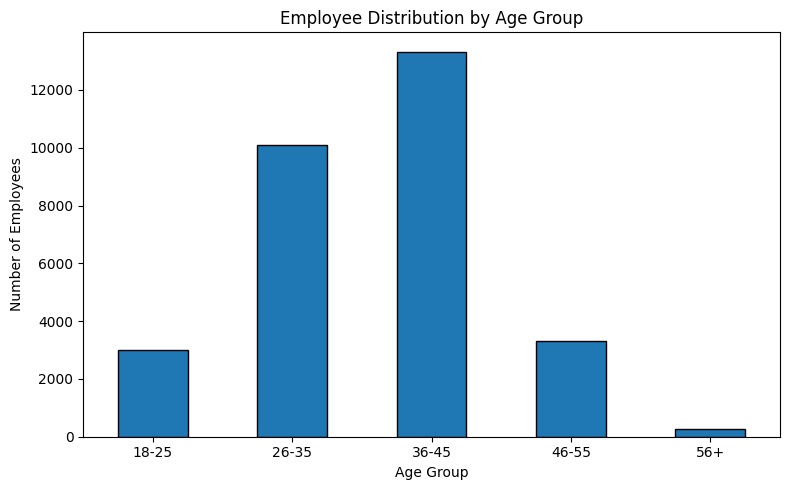

In [ ]:
data_copy["Age_Group"].value_counts().sort_index().plot(
    kind="bar",
    figsize=(8, 5),
    edgecolor="black",
)

plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
data_copy['Gender'].value_counts()

Gender
Male                 13053
Female               12778
Unknown               2512
Prefer not to say      961
Non-binary             696
Name: count, dtype: int64

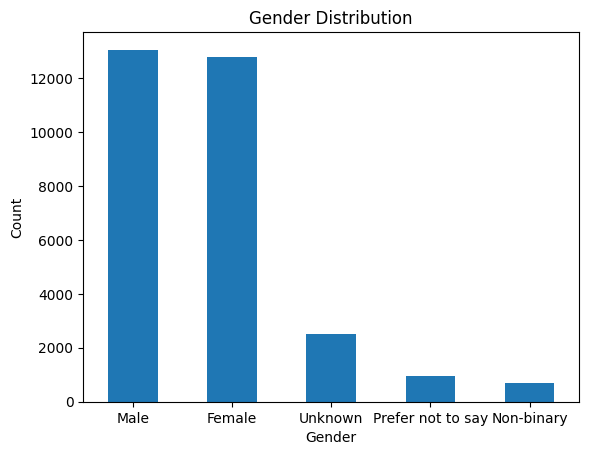

In [21]:
data_copy["Gender"].value_counts().plot(kind="bar")

plt.xlabel("Gender")
plt.ylabel("Count")
plt.title("Gender Distribution")
plt.xticks(rotation=0)
plt.show()

In [22]:
data_copy['Department'].value_counts()

Department
Engineering         5807
Sales               4690
Operations          4582
Customer Support    4230
Marketing           3055
Product             3026
Finance             2814
Human Resources     1796
Name: count, dtype: int64

In [ ]:
data_copy[data_copy['Gender'] == "Female"]['Department'].value_counts()

Department
Engineering         2416
Sales               1992
Operations          1889
Customer Support    1842
Product             1347
Marketing           1325
Finance             1215
Human Resources      752
Name: count, dtype: int64

In [24]:
data_copy[data_copy['Gender'] == "Prefer not to say"]['Department'].value_counts()

Department
Engineering         177
Operations          162
Sales               143
Customer Support    138
Product             118
Marketing            93
Finance              88
Human Resources      42
Name: count, dtype: int64

In [29]:
data_copy.groupby("Age_Group", observed=True)["Department"].value_counts().groupby(level=0 , observed=True).idxmax()

Age_Group
18-25    (18-25, Engineering)
26-35    (26-35, Engineering)
36-45    (36-45, Engineering)
46-55    (46-55, Engineering)
56+        (56+, Engineering)
Name: count, dtype: object